In [1]:
#!pip install pysd netCDF4
import pysd, os
import seaborn as sns
from scipy.optimize import minimize, minimize_scalar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from helper import *

In [31]:
def plotlines(tar, model, pb, ax, title, legend=False, given = [0, 2, 8, 10]):
    
    def runmodel(x, var='alpha'):
        params = pb.copy()
        params[var] = x
        model.reload()
        r = model.run(
                initial_condition='original',
                params=params,
                return_columns=[tar])
        return r
    
    #x = range(37)
    #x = range(t+1)
    
    lb = [round(0.1*i,2) for i in given]
    ys = [runmodel(i)[tar] for i in lb]
    gn = r'$\alpha$'

    x = range(len(ys[0]))


    df = pd.DataFrame({
        "month": np.tile(x, len(lb)),
        tar: np.concatenate(ys),
        gn: np.repeat(lb, len(x))
    })
    
    df[gn] = pd.Categorical([v for v in df[gn]], ordered=True)

    alpha_order = [0.0, 0.2, 0.8, 1.0]

    dashes = {
        0.0: "",
        0.2: (4, 2),
        0.8: (6, 2, 1, 2),
        1.0: (1, 2),
    }

    colors = {
        0.0: '#1f1f1f',   # dark gray
        0.2: '#4d4d4d',
        0.8: '#7f7f7f',
        1.0: '#b2b2b2',   # light gray
    }
    markers = {0.0: "o", 0.2: "^", 0.8: "s", 1.0: "X"}

    sns.lineplot(data=df, x="month", y=tar, hue=gn, style=gn,
                 hue_order=alpha_order, style_order=alpha_order,
                 dashes=dashes, 
                 #markers=markers,
                 color=colors,
                 markevery=6, linewidth=2,
                 palette="viridis",
                 ax=ax, legend=legend)
    
    ax.set_ylabel(None)
    ax.set_title(title)

    ticks = np.linspace(0, len(ys[0]), 7)
    label = np.linspace(0, 30, 7)
    ax.set_xticks(ticks, label)


    return ax

In [2]:
t = 36

In [3]:
#model.components.__dict__.keys()
params_base = {
    'alpha':  0.8, # DM allocation
    'beta':  0.8, # DM policy strength
    'kappa':  0.5, # fan churn rate in response to data-making
    'lambda': 0.0, # motivation decay rate
    'gamma': 0.05, #luren attention
    'maxfactor': 5, # max DM speed
    'w': 0.9, # DM weight in TD aggregation
    's': 0., # luren response to policy theta
    'Reference Arts': 300,
    'Reference Discussion': 50000,
    'Baseline TD': 500000
    }

In [4]:
mod = pysd.read_vensim("FanEconomy251218.mdl")

for name in list(params_base.keys()) :
    print(name, mod[name])

alpha 0.8
beta 0.8
kappa 0.5
lambda 0
gamma 0.1
maxfactor 5
w 0.9
s 0
Reference Arts 300
Reference Discussion 50000
Baseline TD 500000


## Base Model

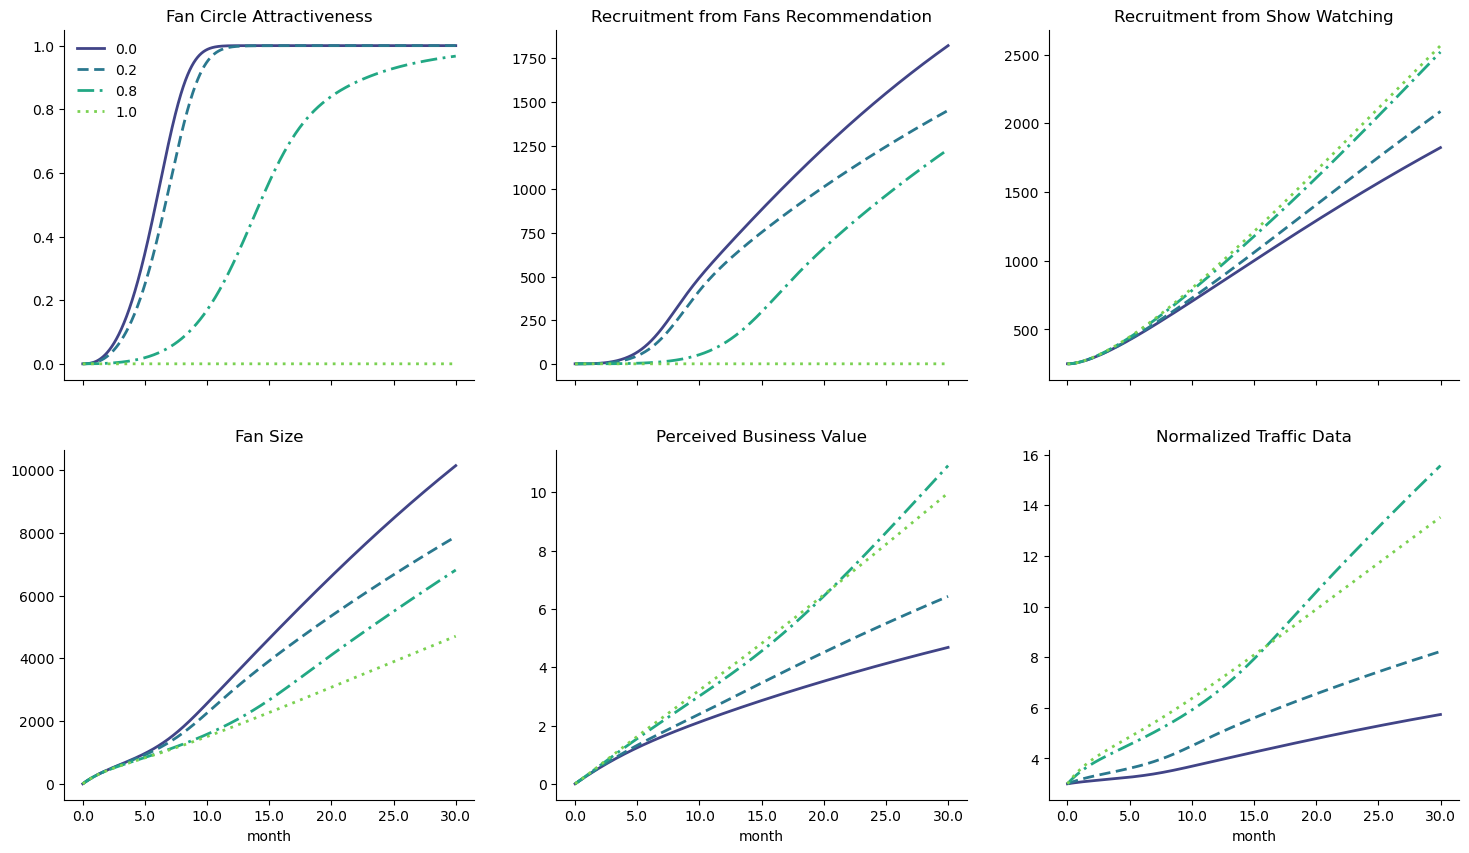

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True)
ax=plotlines('attractiveness_of_fan_circle',  model = mod, pb=params_base, ax=axes[0, 0], title = 'Fan Circle Attractiveness', legend=True)
ax.legend(frameon=False)
plotlines('recruitment_from_fans',  model = mod, ax=axes[0, 1], pb=params_base, title = 'Recruitment from Fans Recommendation')
plotlines('recruitment_from_show_watching',  model = mod, ax=axes[0, 2], pb=params_base, title = 'Recruitment from Show Watching')

plotlines('fan_size',  model = mod, pb=params_base, ax=axes[1,0], title = 'Fan Size')
plotlines('perceived_business_value', model = mod, pb=params_base, ax=axes[1, 1], title ='Perceived Business Value')
plotlines('signal',  pb=params_base, model = mod, ax=axes[1, 2], title = 'Normalized Traffic Data')

sns.despine(right=True, top=True)
plt.show()

In [6]:
def objective(p, tar, ys):
    params = params_base.copy()
    params[tar] = float(p)
    mod.reload()
    res = mod.run(
        initial_condition='original',
        params=params,
        return_columns=[ys]
    )
    final = float(res[ys].iloc[-1])
    return -final

In [7]:
tar = 'alpha'; ys = 'perceived_business_value'
res = minimize_scalar(lambda x: objective(x, tar, ys), 
                      bounds=(0.1, 0.9), method='bounded',
                      options={'xatol': 1e-4, 'maxiter': 200})
print("Best DM:", float(res.x))
print("Max PBV:", -res.fun)

Best DM: 0.8218913917970428
Max PBV: 10.936893381709307


## Platform Strategy

NE points:  [(49, np.int64(41), 9257971.127601245, 12.622911633682584)]
    0.84 1.0


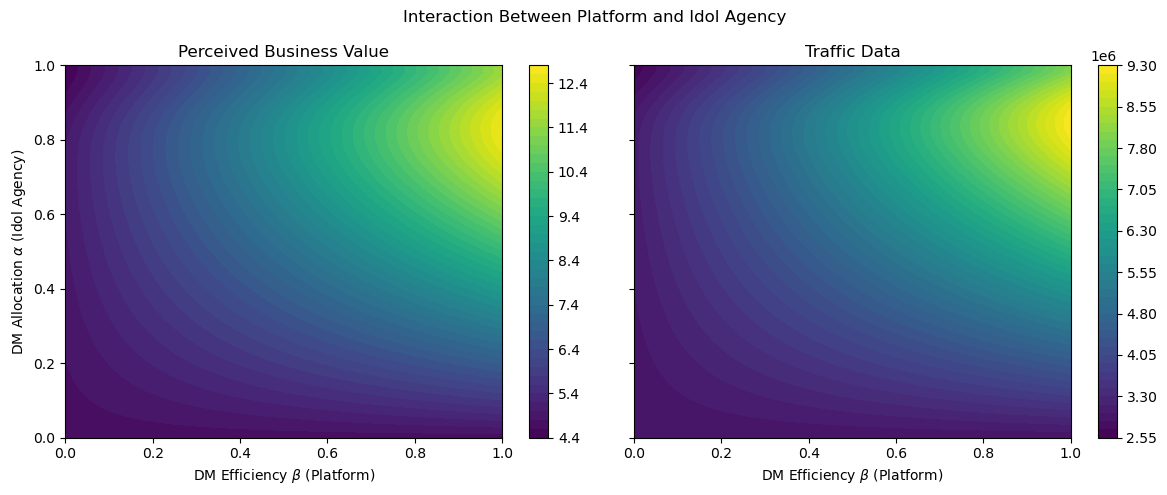

In [8]:
update_params = params_base.copy()
rst = gen_grid(update_params, model = mod,  first = 'alpha', second = 'beta', k=50)
drawPBV_DM(rst, 'Interaction Between Platform and Idol Agency', xlabel = r'DM Efficiency $\beta$ (Platform)')

### Robustness of such strategy

In [5]:
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor, as_completed
from tqdm import tqdm
from filelock import FileLock
import multiprocessing as mp
from functools import partial

In [6]:
print(os.cpu_count())
MODEL_PATH = os.path.abspath("FanEconomy251218.mdl")
LOCK_PATH  = MODEL_PATH + ".pysd_read.lock"
with FileLock(LOCK_PATH):
    _ = pysd.read_vensim(MODEL_PATH)

20


In [7]:
pairs = np.arange(0.05, 1.05, 0.05)
out = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, 'kappa', s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        out[i] = fut.result()

Computing*: 100%|██████████| 20/20 [09:49<00:00, 29.49s/it]


In [8]:
pairs = np.arange(0.0, 0.2, 0.005)
outlambda = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, 'lambda', s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        outlambda[i] = fut.result()

Computing*: 100%|██████████| 40/40 [27:32<00:00, 41.32s/it]


In [9]:
pairs = np.arange(0.05, 1.05, 0.05)
outgamma = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, 'gamma', s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        outgamma[i] = fut.result()

Computing*: 100%|██████████| 20/20 [09:31<00:00, 28.59s/it]


In [24]:
pairs = np.logspace(-2, 2, 20).tolist()
outc = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, tar='t',var=1, c=s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        outc[i] = fut.result()

Computing*: 100%|██████████| 20/20 [09:19<00:00, 27.98s/it]


In [10]:
pairs = np.arange(0.05, 1.05, 0.05)
outs = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, 's', s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        outs[i] = fut.result()

Computing*: 100%|██████████| 20/20 [08:45<00:00, 26.28s/it]


In [11]:
pairs = np.arange(0.05, 1.05, 0.05)
outw = [None] * len(pairs)
with ThreadPoolExecutor(max_workers=20) as ex:
    futures = {ex.submit(findcondition, params_base, MODEL_PATH, 'w', s): i
               for i, s in enumerate(pairs)}
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Computing*"):
        i = futures[fut]
        outw[i] = fut.result()

Computing*: 100%|██████████| 20/20 [19:59<00:00, 59.98s/it] 


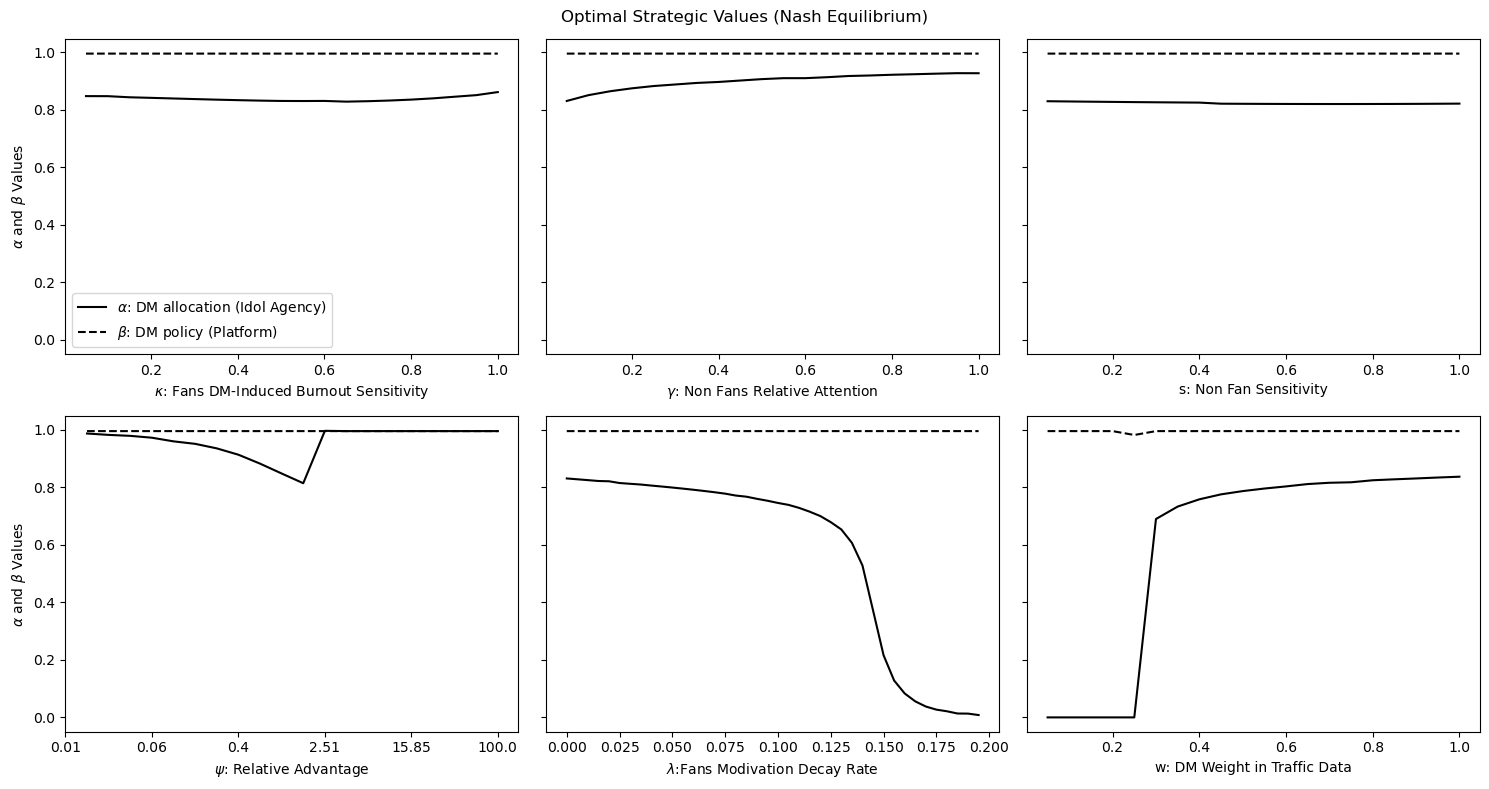

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)

s = np.arange(0.05, 1.05, 0.05)
sns.lineplot(x=s, y=[r[0] for r in out], ax=axes[0,0], label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in out], ax=axes[0,0], label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
axes[0,0].set_xlabel(r'$\kappa$: Fans DM-Induced Burnout Sensitivity')
axes[0,0].set_ylabel(r'$\alpha$ and $\beta$ Values')
#axes[0,0].set_ylim(0,1)

s = np.arange(0.05, 1.05, 0.05)
sns.lineplot(x=s, y=[r[0] for r in outgamma], ax=axes[0,1], label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in outgamma], ax=axes[0,1], label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
axes[0,1].set_xlabel(r'$\gamma$: Non Fans Relative Attention')
axes[0,1].set_ylabel(r'$\alpha$ and $\beta$ Values')
axes[0,1].get_legend().remove()

s = np.arange(0.05, 1.05, 0.05); ax=axes[0,2]
sns.lineplot(x=s, y=[r[0] for r in outs], ax=ax, label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in outs], ax=ax, label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
ax.set_xlabel(r's: Non Fan Sensitivity')
ax.get_legend().remove()

n = np.logspace(-2, 2, 10); ax=axes[1,0]
sns.lineplot(x=s, y=[r[0] for r in outc], ax=ax, label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in outc], ax=ax, label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
ax.set_xlabel(r'$\psi$: Relative Advantage')
ax.set_ylabel(r'$\alpha$ and $\beta$ Values')
#ax.set_ylim(0,1)
ticks = np.arange(0.0, 1.1, 0.2)
label = np.round(np.logspace(-2, 2, len(ticks)),2)
ax.set_xticks(ticks, label)
ax.get_legend().remove()

s = np.arange(0.0, 0.2, 0.005); ax=axes[1,1]
sns.lineplot(x=s, y=[r[0] for r in outlambda], ax=ax, label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in outlambda], ax=ax, label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
ax.set_xlabel(r'$\lambda$:Fans Modivation Decay Rate')
ax.get_legend().remove()

s = np.arange(0.05, 1.05, 0.05); ax=axes[1,2]
sns.lineplot(x=s, y=[r[0] for r in outw], ax=ax, label=r'$\alpha$: DM allocation (Idol Agency)', linestyle='-', color='black')
sns.lineplot(x=s, y=[r[1] for r in outw], ax=ax, label=r'$\beta$: DM policy (Platform)', linestyle='--', color='black')
ax.set_xlabel(r'w: DM Weight in Traffic Data')
ax.get_legend().remove()

plt.suptitle('Optimal Strategic Values (Nash Equilibrium)')
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

## Free Rider

In [12]:
k=50

NE points:  [(49, np.int64(41), 9257971.127601245, 12.622911633682584)]
    0.84 1.0


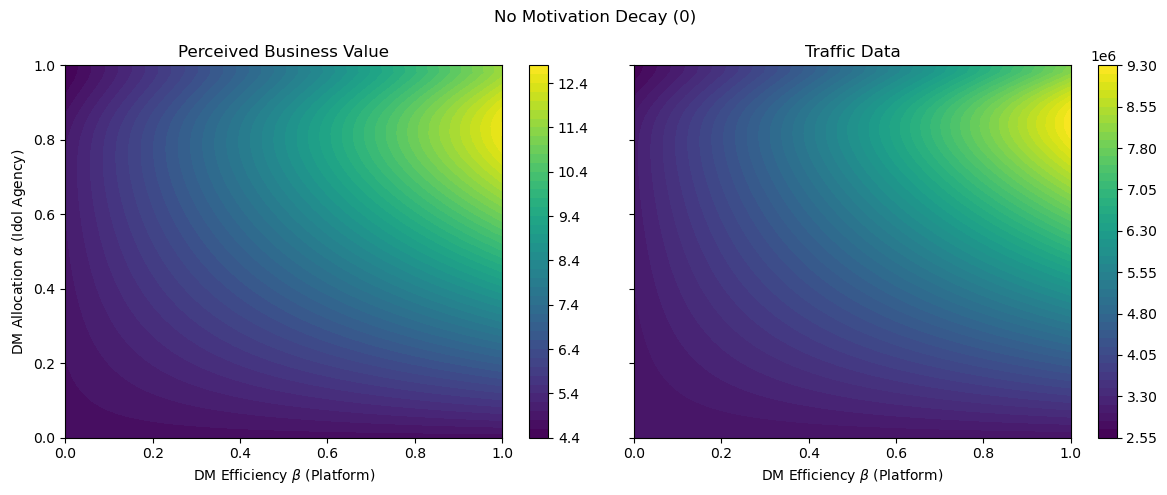

In [13]:
update_params = params_base.copy()
update_params['lambda'] = 0.0
rst = gen_grid(update_params, model = mod,  first = 'alpha', second = 'beta', k=k)
drawPBV_DM(rst, 'No Motivation Decay (0)', xlabel = r'DM Efficiency $\beta$ (Platform)')

NE points:  [(0, np.int64(0), 2869046.272936146, 4.680008984860646), (49, np.int64(11), 2881383.9737484404, 4.7510353485406736)]
    0.0 0.0
    0.22 1.0


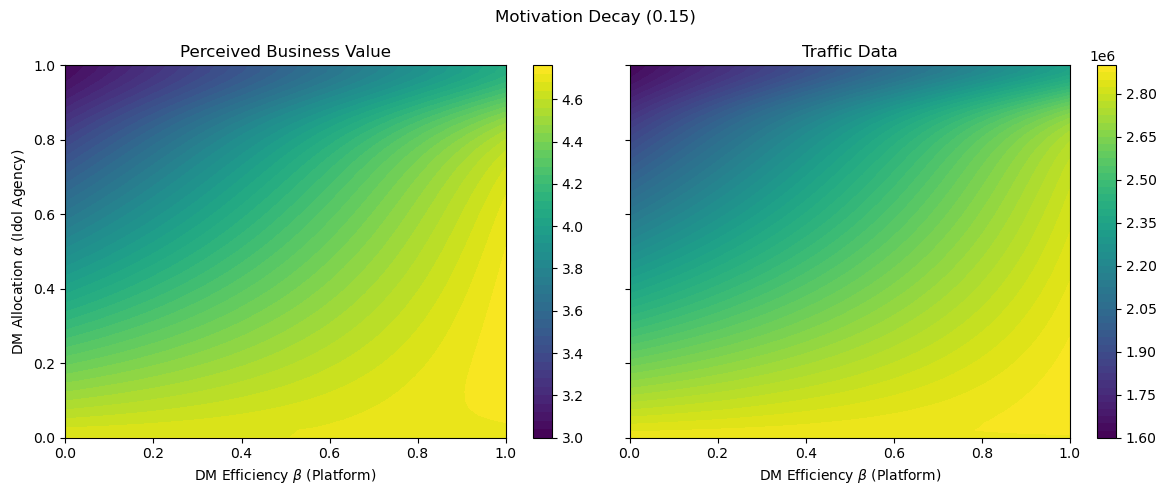

In [14]:
update_params = params_base.copy()
update_params['lambda'] = 0.15
rst = gen_grid(update_params, model = mod,  first = 'alpha', second = 'beta', k=k)
drawPBV_DM(rst, 'Motivation Decay (0.15)', xlabel = r'DM Efficiency $\beta$ (Platform)')

NE points:  [(0, np.int64(0), 2869046.272936146, 4.680008984860646)]
    0.0 0.0


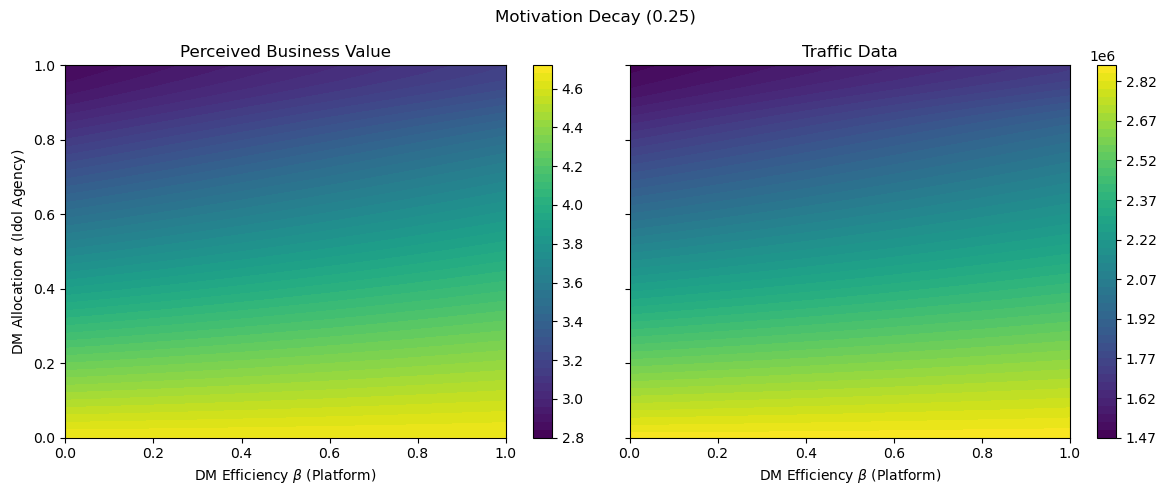

In [15]:
update_params = params_base.copy()
update_params['lambda'] = 0.25
rst = gen_grid(update_params, model = mod,  first = 'alpha', second = 'beta', k=k)
drawPBV_DM(rst, 'Motivation Decay (0.25)', xlabel = r'DM Efficiency $\beta$ (Platform)')

## Path Dependency


In [38]:
def genBA(time, before, after):
    d = np.zeros(t+1); d = d+before; d[time:]=after
    dm = pd.Series(index=range(t+1), data=d)
    return dm

D:\Apps\anaconda\envs\pythonR\Lib\site-packages\pysd\py_backend\model.py:1123: UserWarning: Replacing a constant value with a time-dependent value. The value will be interpolated over time.
  warnings.warn(
D:\Apps\anaconda\envs\pythonR\Lib\site-packages\pysd\py_backend\model.py:1123: UserWarning: Replacing a constant value with a time-dependent value. The value will be interpolated over time.
  warnings.warn(


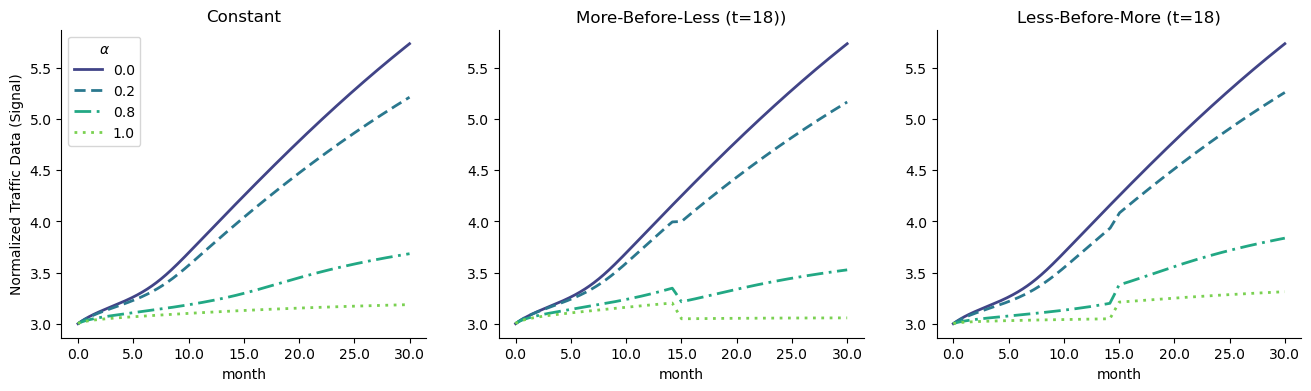

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
scenarios = [genBA(18, 0.5, 0.5), genBA(18, 0.8, 0.2), genBA(18, 0.2, 0.8)]

for col, steps in enumerate(scenarios):
    leg = False
    if col ==0:
        leg = True
        ax.legend(frameon=False)
    plotlines_step(tar='signal', model = mod, pb= params_base,
                   ld=0.25, stepvarvals=steps, legend=leg,
               ax=axes[col], title = None
               #title=f'slacker effect: {r}, sensitivity: {s}'
              )
            
sns.despine(right=True, top=True)

axes[0].set_title('Constant', fontsize=12)
axes[1].set_title('More-Before-Less (t=18))', fontsize=12)
axes[2].set_title('Less-Before-More (t=18)', fontsize=12)

kp = r'$\kappa$'
lm = r'$\lambda$'

axes[0].set_ylabel('Normalized Traffic Data (Signal)')
#axes[0].set_ylabel(f'Motivation Decay ({lm}=0.1)', fontsize=12, labelpad=20)

plt.show()

In [42]:
def plotlines_step(tar, ax, model, 
                   stepvarvals, pb, legend,
                   ld=0.1,  
                   given = [0, 2, 8, 10],
                   title = None): 
    
    stepvar='beta'
    def runmodel(a, ld, stepvar, stepvarvals, pb):
        model.reload()
        params = pb.copy()

        params['alpha'] = a
        params['lambda'] = ld
        params['beta'] = stepvarvals
        
        r = model.run(
                initial_condition='original',
                params=params,
                return_columns=[tar])
        return r
    
    
    lb = [round(0.1*i,2) for i in given]
    ys = [runmodel(i, ld=ld, stepvar=stepvar, 
                   stepvarvals=stepvarvals, pb=pb)[tar] for i in lb]
    x = range(len(ys[0]))
    gn = r'$\alpha$'
    df = pd.DataFrame({
        "month": np.tile(x, len(lb)),
        tar: np.concatenate(ys),
        gn: np.repeat(lb, len(x))
    })
    
    df[gn] = pd.Categorical([v for v in df[gn]], ordered=True)

    alpha_order = [0.0, 0.2, 0.8, 1.0]

    dashes = {
        0.0: "",
        0.2: (4, 2),
        0.8: (6, 2, 1, 2),
        1.0: (1, 2),
    }

    colors = {
        0.0: '#1f1f1f',   # dark gray
        0.2: '#4d4d4d',
        0.8: '#7f7f7f',
        1.0: '#b2b2b2',   # light gray
    }
    markers = {0.0: "o", 0.2: "^", 0.8: "s", 1.0: "X"}

    sns.lineplot(data=df, x="month", y=tar, hue=gn, style=gn,
                 hue_order=alpha_order, style_order=alpha_order,
                 dashes=dashes, 
                 #markers=markers,
                 color=colors,
                 markevery=6, linewidth=2,
                 palette="viridis",
                 ax=ax, legend=legend)
    ax.set_ylabel(None)
    ax.set_title(title)
    ticks = np.linspace(0, len(ys[0]), 7)
    label = np.linspace(0, 30, 7)
    ax.set_xticks(ticks, label)
    
   
    return ax